# 1. Imports

In [1]:
import os
import glob
import math

import numpy as np
import pandas as pd
import librosa
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

print("librosa:", librosa.__version__)

librosa: 0.11.0


# 2. Configs

Produces the same format as `Bauls_melspec.npy`: one `.npy` per class, holding
ALL of that class's fixed-size mel-spectrogram chunks stacked into a single
array of shape `(n_chunks, N_MELS, EXPECTED_FRAMES)` -- e.g. `(20223, 128, 130)`.

Each song is cut into non-overlapping `SEGMENT_DURATION`-second segments
(3s by default), and each segment becomes one mel-spectrogram "row" in the
class's array. With SR=22050, N_FFT=2048, HOP_LENGTH=512, a 3s segment
produces exactly 130 time frames -- this is a standard, widely-used
convention for spectrogram-chunk audio classification.

Folder layout expected (same as your raga dataset):
```
AUDIO_ROOT/
  <raga_id_uuid>/
    <artist_name>/
      <raag_folder>/
        recording.wav
```


In [2]:
AUDIO_ROOT = "/kaggle/input/datasets/mishbhaul/indian-raga-dataset/RagaDataset/Hindustani/audio/"
OUTPUT_DIR = "/kaggle/working/melspec_chunks/"
MANIFEST_PATH = os.path.join(OUTPUT_DIR, "manifest.csv")

AUDIO_EXTENSIONS = (".wav", ".mp3", ".flac", ".m4a")

SR = 22050
N_FFT = 2048
HOP_LENGTH = 512
N_MELS = 128
SEGMENT_DURATION = 3.0  # seconds per chunk

SEGMENT_SAMPLES = int(SEGMENT_DURATION * SR)
EXPECTED_FRAMES = math.ceil(SEGMENT_SAMPLES / HOP_LENGTH)  # -> 130 with defaults above

os.makedirs(OUTPUT_DIR, exist_ok=True)
print(f"Segment: {SEGMENT_DURATION}s = {SEGMENT_SAMPLES} samples -> {EXPECTED_FRAMES} mel frames")

id_to_raga = {
    'f7fddfc0-8c1d-4dd2-90d5-5d51a99d61f8 2': 'Rāgēśrī',
    'f6432fec-e9c2-4b09-9e73-c46086cbd8ea': 'Ahira bhairav',
    '290674e0-d94c-41c1-ad99-f65fa22a1447': 'Madhuvanti',
    '0b3bbf97-0ec3-41da-add4-722d87329ec3': 'Madhukauns',
    'a9ee554f-f146-43e9-b2d0-9bb31fd4b57d': 'Kēdār',
    'd9c603fa-875f-4b84-b851-c6a345427898': 'Ābhōgī',
    '1e7de02f-e77f-405a-a033-f31117aaf955': 'Bhairav',
    '3eb7ba30-4b94-432e-9618-875ee57e01ab': 'Mārvā',
    '46997b02-f09c-4969-8138-4e1861f61967': 'Śrī',
    '54c4214c-05b9-4acc-8f77-6d5786e43a2e': 'Mārūbihāg',
    'a99e07d5-20a0-467b-8dcd-aa5a095177fd': 'Lalit',
    '62b79291-73b0-4c77-a353-0f8bc6ed8362': 'Dēś',
    '118401e7-8de8-4d81-9d8e-8070889e3fa8': 'Darbāri',
    '7591faad-e68a-4550-b675-8082842c6056': 'Bāgēśrī',
    '93c73081-bdf8-4eca-b325-d736b71e9b4b': 'Khamāj',
    'ba3242d0-8d40-4d93-865e-d2e2497ea2a8': 'Gauḍ malhār',
    'ecd04ceb-b46c-47fc-9045-84ac9160e527': 'Basant',
    '6f13484e-6fdd-402d-baf3-3835835454d0': 'Tōḍī',
    'fa28470c-d413-44c7-94da-181f530cbfdd': 'Puriyā dhanaśrī',
    'f7fddfc0-8c1d-4dd2-90d5-5d51a99d61f8': 'Rāgēśrī',
    '40dbe1db-858f-4366-bef8-9076eb67340d': 'Śuddh sāraṅg',
    '1b05a564-059f-445b-b325-cf26318367e3': 'Miyān malhār',
    'b143adaa-f1a6-4de4-8985-a5bd35e96279': 'Bairāgi',
    '64e5fb9e-5569-4e80-8e6c-f543af9469c7': 'Mālkauns',
    '2ed9379f-14c9-49af-8e4d-f9b63e96801f': 'Alahaiyā bilāval',
    'e771a74d-545d-41d5-816b-43403a818b0c': 'Bhūp',
    '063ea5a0-23b1-4bb5-8537-3d924fe8ebb3': 'Jōg',
    'a7d98897-e2fe-4d75-b9dc-e5b4dc88e1c6': 'Bihāg',
    '48b37bed-e847-4882-8a01-5c721e07f07d': 'Yaman kalyāṇ',
    '595de771-fcc2-414c-9df6-ae4ffd898549': 'Hamsadhvāni',
    'dd59147d-8775-44ff-a36b-0d9f15b31319': 'Bilāsakhānī tōḍī',
}

Segment: 3.0s = 66150 samples -> 130 mel frames


# 3. Song -> chunked mel-spectrograms

In [3]:
def song_to_mel_chunks(path):
    """Loads one song, cuts it into non-overlapping SEGMENT_DURATION-second
    windows, and returns a list of (N_MELS, EXPECTED_FRAMES) mel-spectrograms
    in dB -- one per full segment. The final partial segment (shorter than
    SEGMENT_DURATION) is dropped, matching a fixed-shape output array."""
    y, _ = librosa.load(path, sr=SR, mono=True)

    chunks = []
    n_segments = len(y) // SEGMENT_SAMPLES
    for i in range(n_segments):
        start = i * SEGMENT_SAMPLES
        end = start + SEGMENT_SAMPLES
        segment = y[start:end]

        mel = librosa.feature.melspectrogram(
            y=segment, sr=SR, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS
        )
        mel_db = librosa.power_to_db(mel, ref=np.max)

        # guard against off-by-one frame counts from librosa's framing
        if mel_db.shape[1] != EXPECTED_FRAMES:
            if mel_db.shape[1] > EXPECTED_FRAMES:
                mel_db = mel_db[:, :EXPECTED_FRAMES]
            else:
                pad = EXPECTED_FRAMES - mel_db.shape[1]
                mel_db = np.pad(mel_db, ((0, 0), (0, pad)), mode="constant",
                                 constant_values=mel_db.min())

        chunks.append(mel_db.astype(np.float32))

    return chunks

# 4. Process all classes/songs

Alongside each `<label>_melspec.npy`, this also saves a parallel
`<label>_songs.npy` array of the SAME LENGTH -- `songs[i]` is the source
song filename that chunk `melspec[i]` came from. This is what lets you do
a correct song-level train/val/test split later: group chunk indices by
this array, split the *unique song names*, then select chunks by group so
no song's chunks end up split across train and val.

In [4]:
# group raga_ids by label FIRST -- some labels have more than one folder
# (e.g. a duplicate-named folder Kaggle appended " 2" to), and all of them
# need to be merged into one array per label, not overwritten one after another
label_to_ids = {}
for raga_id, label in id_to_raga.items():
    label_to_ids.setdefault(label, []).append(raga_id)

dupe_labels = {lbl: ids for lbl, ids in label_to_ids.items() if len(ids) > 1}
if dupe_labels:
    print("NOTE: these labels map to multiple raga_id folders and will be merged:")
    for lbl, ids in dupe_labels.items():
        print(f"  {lbl}: {ids}")

manifest_rows = []
missing_ids = []

for label, raga_ids in tqdm(label_to_ids.items(), desc="Ragas"):
    label_chunks = []
    label_songs = []   # parallel array: which song each chunk came from
    total_songs = 0
    found_any_folder = False

    for raga_id in raga_ids:
        class_dir = os.path.join(AUDIO_ROOT, raga_id)
        if not os.path.isdir(class_dir):
            missing_ids.append((raga_id, label))
            continue
        found_any_folder = True

        audio_files = sorted([
            f for f in glob.glob(os.path.join(class_dir, "**", "*"), recursive=True)
            if f.lower().endswith(AUDIO_EXTENSIONS)
        ])
        total_songs += len(audio_files)

        for audio_path in tqdm(audio_files, desc=f"{label} ({raga_id[:8]})", leave=False):
            try:
                chunks = song_to_mel_chunks(audio_path)
            except Exception as e:
                print(f"[SKIPPED] {audio_path}: {e}")
                continue

            song_id = os.path.basename(audio_path)  # unique enough within a label
            label_chunks.extend(chunks)
            label_songs.extend([song_id] * len(chunks))

    if not found_any_folder:
        continue  # already recorded in missing_ids above

    if not label_chunks:
        print(f"[WARNING] No chunks produced for {label}")
        continue

    label_array = np.stack(label_chunks, axis=0)  # (n_chunks, N_MELS, EXPECTED_FRAMES)
    songs_array = np.array(label_songs)            # (n_chunks,) -- source song per chunk

    safe_label = label.replace(" ", "_")
    spec_path = os.path.join(OUTPUT_DIR, f"{safe_label}_melspec.npy")
    songs_path = os.path.join(OUTPUT_DIR, f"{safe_label}_songs.npy")
    np.save(spec_path, label_array)
    np.save(songs_path, songs_array)

    manifest_rows.append({
        "label": label,
        "raga_ids": ";".join(raga_ids),
        "n_songs": total_songs,
        "n_chunks": label_array.shape[0],
        "melspec_file": os.path.basename(spec_path),
        "songs_file": os.path.basename(songs_path),
        "shape": str(label_array.shape),
    })
    print(f"{label}: {total_songs} songs -> {label_array.shape}")

if missing_ids:
    print(f"\n[WARNING] {len(missing_ids)} raga_id(s) had no matching folder under {AUDIO_ROOT}:")
    for rid, lbl in missing_ids:
        print(f"  {rid} ({lbl})")

NOTE: these labels map to multiple raga_id folders and will be merged:
  Rāgēśrī: ['f7fddfc0-8c1d-4dd2-90d5-5d51a99d61f8 2', 'f7fddfc0-8c1d-4dd2-90d5-5d51a99d61f8']


Ragas:   0%|          | 0/30 [00:00<?, ?it/s]

Rāgēśrī (f7fddfc0):   0%|          | 0/1 [00:00<?, ?it/s]

Rāgēśrī (f7fddfc0):   0%|          | 0/9 [00:00<?, ?it/s]

Rāgēśrī: 10 songs -> (4012, 128, 130)


...

Yaman kalyāṇ: 10 songs -> (5030, 128, 130)


Hamsadhvāni (595de771):   0%|          | 0/10 [00:00<?, ?it/s]

Hamsadhvāni: 10 songs -> (2882, 128, 130)


Bilāsakhānī tōḍī (dd59147d):   0%|          | 0/10 [00:00<?, ?it/s]

Bilāsakhānī tōḍī: 10 songs -> (4534, 128, 130)


# 5. Save manifest

In [5]:
manifest = pd.DataFrame(manifest_rows)
manifest.to_csv(MANIFEST_PATH, index=False)
print(f"Manifest saved to {MANIFEST_PATH}")
manifest

Manifest saved to /kaggle/working/melspec_chunks/manifest.csv


,label,raga_ids,n_songs,n_chunks,melspec_file,songs_file,shape
0,Rāgēśrī,f7fddfc0-8c1d-4dd2-90d5-5d51a99d61f8 2;f7fddfc...,10,4012,Rāgēśrī_melspec.npy,Rāgēśrī_songs.npy,"(4012, 128, 130)"
1,Ahira bhairav,f6432fec-e9c2-4b09-9e73-c46086cbd8ea,10,3762,Ahira_bhairav_melspec.npy,Ahira_bhairav_songs.npy,"(3762, 128, 130)"
2,Madhuvanti,290674e0-d94c-41c1-ad99-f65fa22a1447,10,4798,Madhuvanti_melspec.npy,Madhuvanti_songs.npy,"(4798, 128, 130)"
3,Madhukauns,0b3bbf97-0ec3-41da-add4-722d87329ec3,10,3420,Madhukauns_melspec.npy,Madhukauns_songs.npy,"(3420, 128, 130)"
4,Kēdār,a9ee554f-f146-43e9-b2d0-9bb31fd4b57d,10,3975,Kēdār_melspec.npy,Kēdār_songs.npy,"(3975, 128, 130)"
5,Ābhōgī,d9c603fa-875f-4b84-b851-c6a345427898,10,3955,Ābhōgī_melspec.npy,Ābhōgī_songs.npy,"(3955, 128, 130)"
6,Bhairav,1e7de02f-e77f-405a-a033-f31117aaf955,10,3932,Bhairav_melspec.npy,Bhairav_songs.npy,"(3932, 128, 130)"
7,Mārvā,3eb7ba30-4b94-432e-9618-875ee57e01ab,10,4858,Mārvā_melspec.npy,Mārvā_songs.npy,"(4858, 128, 130)"
8,Śrī,46997b02-f09c-4969-8138-4e1861f61967,10,7285,Śrī_melspec.npy,Śrī_songs.npy,"(7285, 128, 130)"
9,Mārūbihāg,54c4214c-05b9-4acc-8f77-6d5786e43a2e,10,4974,Mārūbihāg_melspec.npy,Mārūbihāg_songs.npy,"(4974, 128, 130)"


<Label>_melspec.npy — the actual data. Shape (n_chunks, 128, 130): every chunk's mel-spectrogram, stacked.

<Label>_songs.npy — the labels-for-the-labels, so to speak. Shape (n_chunks,): for every single chunk in the melspec array, this tells you which source song it came from. songs[i] is the filename of the song that produced melspec[i].

# 6. Sanity check: load one class back and view a chunk

Label: Rāgēśrī | shape: (4012, 128, 130) | songs array len: 4012
Distinct songs in this class: 10
Chunk 0 came from song: Raag_Rageshri_9a2ce15a-4b28-4d10-abc7-9e05310c2e3b.mp3


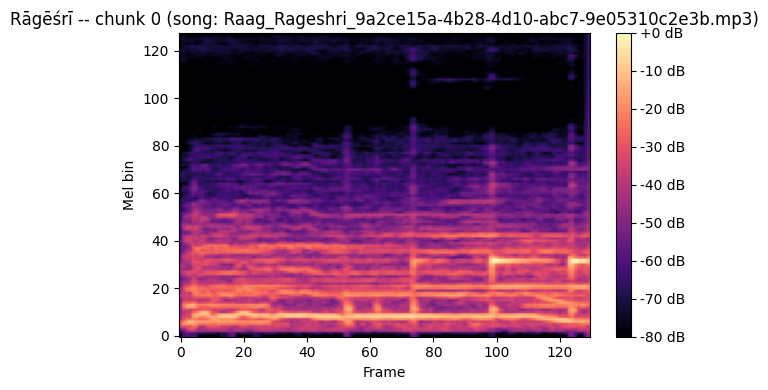

In [6]:
sample_row = manifest.iloc[0]
sample_array = np.load(os.path.join(OUTPUT_DIR, sample_row["melspec_file"]))
sample_songs = np.load(os.path.join(OUTPUT_DIR, sample_row["songs_file"]), allow_pickle=True)
print(f"Label: {sample_row['label']} | shape: {sample_array.shape} | songs array len: {len(sample_songs)}")
print(f"Distinct songs in this class: {len(set(sample_songs))}")
print(f"Chunk 0 came from song: {sample_songs[0]}")

plt.figure(figsize=(6, 4))
plt.imshow(sample_array[0], aspect="auto", origin="lower", cmap="magma")
plt.colorbar(format="%+2.0f dB")
plt.title(f"{sample_row['label']} -- chunk 0 (song: {sample_songs[0]})")
plt.xlabel("Frame")
plt.ylabel("Mel bin")
plt.tight_layout()
plt.show()

# 7. Download

In [8]:
import shutil
shutil.make_archive('/kaggle/working/melspec_chunks', 'zip', '/kaggle/working/melspec_chunks')

'/kaggle/working/melspec_chunks.zip'